# **1. Setup & Environment**



## 1.1 Install Dependencies

In [ ]:
!pip install -q torch_geometric transformers shap lime wordcloud --upgrade
print("Dependencies installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 32.8 MB/s eta 0:00:00
Dependencies installed.


## 1.2 Import Libraries

In [ ]:
import os, re, time, random, warnings, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report)

from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
print("Libraries imported.")

Libraries imported.


## 1.3 Configuration & Reproducibility


In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

CONFIG = {
    "DATA_PATH": "enron_spam_data.csv",
    "SAMPLE_SIZE": 12000,

    "TEST_SIZE": 0.15,
    "VAL_SIZE": 0.15,

    "MAX_LEN": 128,

    "BERT_MODEL": "distilbert-base-uncased",
    "BERT_EPOCHS": 2,
    "BERT_BATCH_SIZE": 32,
    "BERT_LR": 2e-5,

    "KNN_K": 8,

    "GNN_HIDDEN": 128,
    "GNN_EPOCHS": 100,
    "GNN_LR": 0.01,
    "GNN_WEIGHT_DECAY": 5e-4,
    "GNN_DROPOUT": 0.3,
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: no GPU detected. Go to Runtime > Change runtime type > T4 GPU for a big speed-up.")

Using device: cuda



# **2. Data Loading**




## 2.1 Upload / Locate the Dataset

In [ ]:
from google.colab import files
import zipfile, io, os

if not os.path.exists(CONFIG["DATA_PATH"]):
    print("Please upload 'enron_spam_data_csv.zip' or 'enron_spam_data.csv' when prompted...")
    uploaded = files.upload()
    for fname in uploaded.keys():
        if fname.endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(uploaded[fname])) as z:
                z.extractall(".")

    csvs = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "enron" in f.lower()]
    if csvs:
        CONFIG["DATA_PATH"] = csvs[0]

print("Using data file:", CONFIG["DATA_PATH"])

Using data file: enron_spam_data.csv


## 2.2 Load & Inspect

In [ ]:
df_raw = pd.read_csv(CONFIG["DATA_PATH"], engine='python', on_bad_lines='warn')
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (19833, 424)


,Subject,Message,Spam/Ham,Date,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 414,Unnamed: 415,Unnamed: 416,Unnamed: 417,Unnamed: 418,Unnamed: 419,Unnamed: 420,Unnamed: 421,Unnamed: 422,Unnamed: 423
0,christmas tree farm pictures,NaN,ham,12/10/1999,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"vastar resources , inc .","gary , production from the high island larger ...",ham,12/13/1999,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,12/14/1999,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,re : issue,fyi - see note below - already done .\nstella\...,ham,12/14/1999,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,12/14/1999,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19833 entries, 0 to 19832
Columns: 424 entries, Subject to Unnamed: 423
dtypes: float64(3), object(421)
memory usage: 64.2+ MB


In [ ]:
df_raw.isna().sum().to_frame("missing_values")

,missing_values
Subject,10653
Message,2873
Spam/Ham,4364
Date,5189
Unnamed: 4,14808
...,...
Unnamed: 419,19830
Unnamed: 420,19830
Unnamed: 421,19830
Unnamed: 422,19830


## 2.3 Data-Integrity Gate (runs before any cleaning, sampling or split)

In [ ]:
import hashlib, sys, sklearn

STRICT_GATE = False
MIN_DISTINCT_PER_CLASS = 100

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

try:
    torch_v = torch.__version__
except NameError:
    torch_v = "n/a"
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| torch", torch_v, "| seed", SEED)
print("Data file:", CONFIG["DATA_PATH"], "| SHA-256:", sha256_of(CONFIG["DATA_PATH"])[:16] + "...")

df_gate = pd.read_csv(CONFIG["DATA_PATH"])
print("Gate shape:", df_gate.shape, "| columns:", list(df_gate.columns))
if "df_raw" in globals() and df_raw.shape != df_gate.shape:
    print(f"WARNING: df_raw {df_raw.shape} differs from the default parse {df_gate.shape}; "
          "the notebook-loaded structure is not the structure of the file on disk.")

df_gate["Subject"] = df_gate["Subject"].fillna("")
df_gate["Message"] = df_gate["Message"].fillna("")
df_gate["text"] = (df_gate["Subject"] + " . " + df_gate["Message"]).str.strip()
df_gate["label"] = (df_gate["Spam/Ham"].astype(str).str.strip().str.lower() == "spam").astype(int)
df_gate["gid"] = df_gate["text"].map(lambda t: hashlib.md5(t.encode()).hexdigest())

n_rows, n_distinct = len(df_gate), df_gate["gid"].nunique()
print(f"Rows: {n_rows} | distinct combined texts: {n_distinct} | duplicate rows: {n_rows - n_distinct}")
per_class = df_gate.groupby("label")["gid"].agg(rows="size", distinct="nunique")
per_class.index = ["ham", "spam"]
print(per_class)
both = int((df_gate.groupby("gid")["label"].nunique() > 1).sum())
print("Texts carrying both labels:", both)

gate_ok = per_class["distinct"].min() >= MIN_DISTINCT_PER_CLASS
print("INTEGRITY GATE:", "PASS" if gate_ok else f"FAIL (a class has fewer than {MIN_DISTINCT_PER_CLASS} distinct texts)")
if STRICT_GATE and not gate_ok:
    raise RuntimeError("Integrity gate failed: do not train on this corpus.")

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | torch n/a | seed 42
Data file: data/enron_spam_data.csv | SHA-256: 6bba82025050aeaa...
Gate shape: (33716, 5) | columns: ['Unnamed: 0', 'Subject', 'Message', 'Spam/Ham', 'Date']
Rows: 33716 | distinct combined texts: 15910 | duplicate rows: 17806
       rows  distinct
ham   16545     15910
spam  17171         6
Texts carrying both labels: 6
INTEGRITY GATE: FAIL (a class has fewer than 100 distinct texts)


# **3. Exploratory Data Analysis (EDA)**


## 3.1 Data Quality & Cleaning of Obvious Issues

In [ ]:
df = df_raw.copy()

rename_map = {c: c.strip() for c in df.columns}
df = df.rename(columns=rename_map)
df = df.rename(columns={"Spam/Ham": "label_text"})

df["Subject"] = df["Subject"].fillna("")
df["Message"] = df["Message"].fillna("")
df["text"] = (df["Subject"] + " . " + df["Message"]).str.strip()

before_text_filter = len(df)
df = df[df["text"].str.len() > 0].reset_index(drop=True)
print(f"Dropped {before_text_filter - len(df)} rows with empty subject+message. Remaining: {len(df)}")

initial_len = len(df)
df["label_text"] = df["label_text"].astype(str).str.strip().str.lower()
df = df[df["label_text"].isin(["spam", "ham"])].reset_index(drop=True)
print(f"Dropped {initial_len - len(df)} rows with invalid label_text. Remaining: {len(df)}")

df["label"] = (df["label_text"] == "spam").astype(int)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Rows with unparsable dates:", df["Date"].isna().sum())

df = df[["Subject", "Message", "label_text", "label", "Date", "text"]]

df.head(3)

Dropped 0 rows with empty subject+message. Remaining: 19833
Dropped 10637 rows with invalid label_text. Remaining: 9196
Rows with unparsable dates: 0


,Subject,Message,label_text,label,Date,text
0,christmas tree farm pictures,,ham,0,1999-12-10,christmas tree farm pictures .
1,"vastar resources , inc .","gary , production from the high island larger ...",ham,0,1999-12-13,"vastar resources , inc . . gary , production f..."
2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,0,1999-12-14,calpine daily gas nomination . - calpine daily...


## 3.2 Class Distribution — Spam vs. Ham

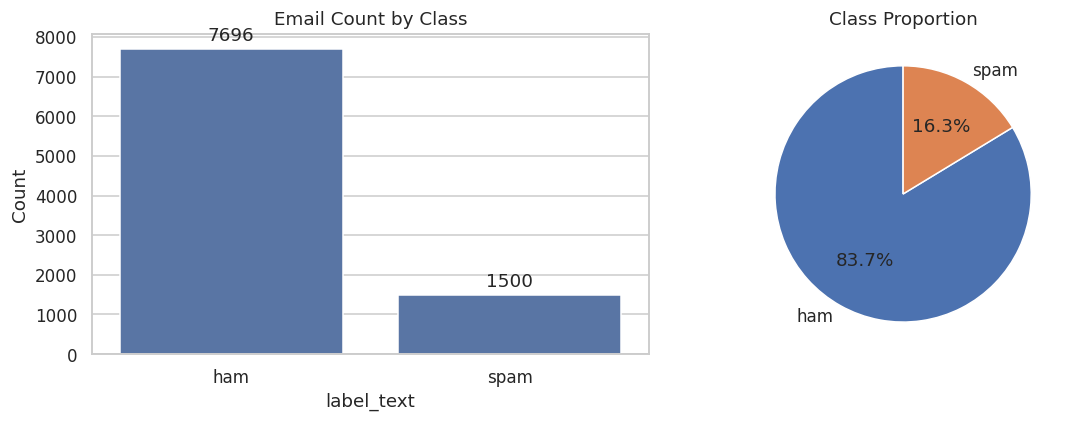

label_text
ham     7696
spam    1500
Name: count, dtype: int64

Spam share = 16.31% -> the dataset is imbalanced, so stratified splitting is used and precision, recall and F1 are reported besides accuracy.


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = df["label_text"].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax[0])
ax[0].set_title("Email Count by Class")
ax[0].set_ylabel("Count")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 200, str(v), ha="center")

ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=sns.color_palette("deep")[:2])
ax[1].set_title("Class Proportion")
plt.tight_layout(); plt.show()

print(counts)
print(f"\nSpam share = {counts['spam']/counts.sum():.2%} -> the dataset is imbalanced, so stratified splitting is used and precision, recall and F1 are reported besides accuracy.")

## 3.3 Text Length Distributions

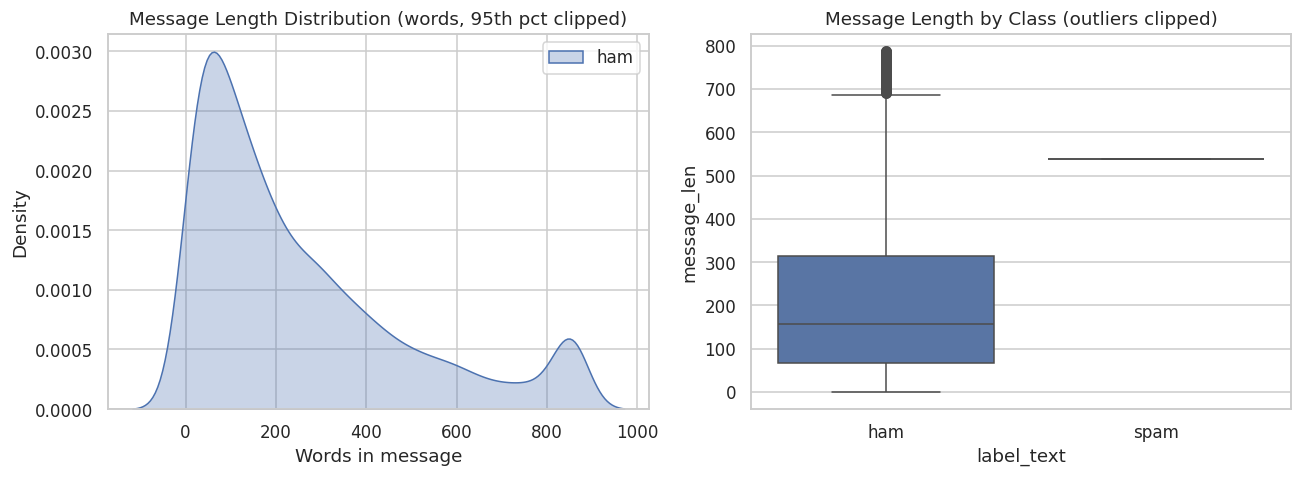

label_text                 ham    spam
subject_len count  7696.000000  1500.0
            mean      5.975962     4.0
            std       3.736801     0.0
            min       0.000000     4.0
            25%       3.000000     4.0
            50%       5.000000     4.0
            75%       8.000000     4.0
            max      71.000000     4.0
message_len count  7696.000000  1500.0
            mean    275.947375   538.0
            std     343.930194     0.0
            min       0.000000   538.0
            25%      71.000000   538.0
            50%     171.000000   538.0
            75%     361.000000   538.0
            max    8851.000000   538.0
total_len   count  7696.000000  1500.0
            mean    282.923337   543.0
            std     344.300892     0.0
            min       2.000000   543.0
            25%      78.000000   543.0
            50%     178.000000   543.0
            75%     368.000000   543.0
            max    8862.000000   543.0

In [ ]:
df["subject_len"] = df["Subject"].str.split().str.len()
df["message_len"] = df["Message"].str.split().str.len()
df["total_len"]   = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for lbl, color in zip(["ham", "spam"], ["#4C72B0", "#C44E52"]):
    subset = df[df["label_text"] == lbl]["message_len"]
    sns.kdeplot(subset.clip(upper=subset.quantile(0.95)), label=lbl, fill=True, alpha=0.3, ax=axes[0], color=color)
axes[0].set_title("Message Length Distribution (words, 95th pct clipped)")
axes[0].set_xlabel("Words in message"); axes[0].legend()

sns.boxplot(x="label_text", y="message_len", data=df[df["message_len"] < df["message_len"].quantile(0.95)], ax=axes[1])
axes[1].set_title("Message Length by Class (outliers clipped)")
plt.tight_layout(); plt.show()

df.groupby("label_text")[["subject_len", "message_len", "total_len"]].describe().T

## 3.4 Temporal Trends — Spam vs. Ham Over Time


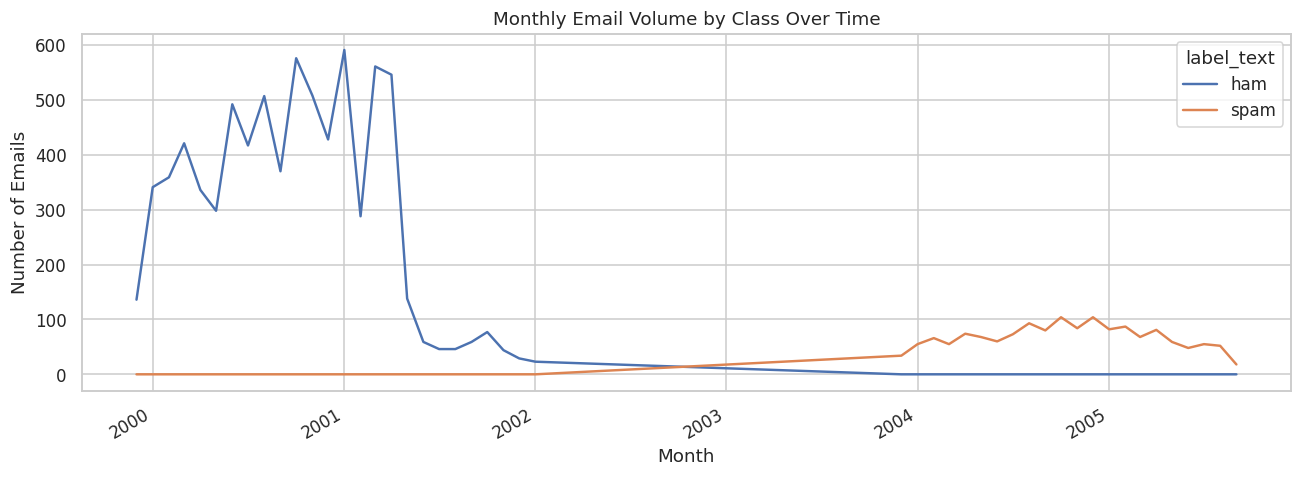

Date range: 1999-12-10 to 2005-09-06


In [ ]:
df_time = df.dropna(subset=["Date"]).copy()
df_time["year_month"] = df_time["Date"].dt.to_period("M").dt.to_timestamp()

monthly = df_time.groupby(["year_month", "label_text"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.5))
monthly.plot(ax=ax, linewidth=1.6)
ax.set_title("Monthly Email Volume by Class Over Time")
ax.set_xlabel("Month"); ax.set_ylabel("Number of Emails")
plt.tight_layout(); plt.show()

print("Date range:", df_time["Date"].min().date(), "to", df_time["Date"].max().date())

## 3.5 Most Frequent Words — Spam vs. Ham (N-gram Analysis)

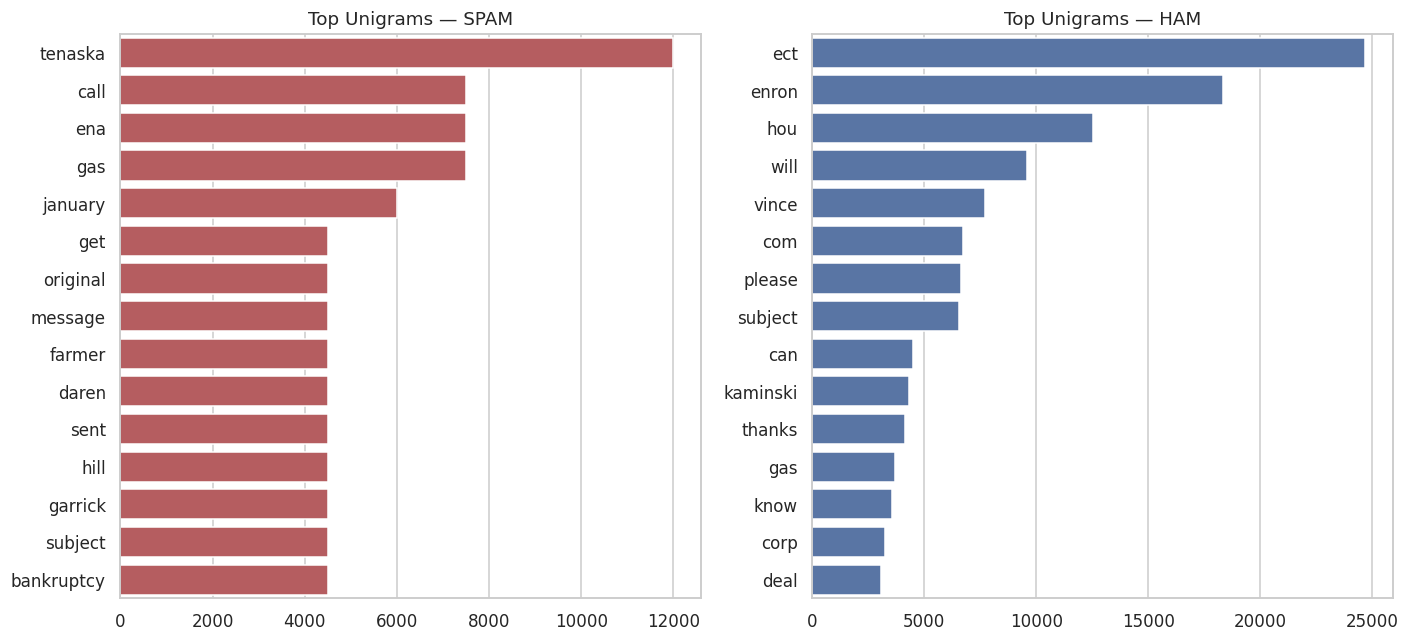

In [ ]:
from collections import Counter
import string

_stopwords_text = (
    "a about above after again against all am an and any are arent as at be because been "
    "before being below between both but by cant cannot could couldnt did didnt do does doesnt doing dont "
    "down during each few for from further had hadnt has hasnt have havent having he hed hell hes her here "
    "heres hers herself him himself his how hows i id ill im ive if in into is isnt it its itself "
    "lets me more most mustnt my myself no nor not of off on once only or other ought our ours ourselves out "
    "over own same shant she shed shell shes should shouldnt so some such than that thats the their theirs "
    "them themselves then there theres these they theyd theyll theyre theyve this those through to too "
    "under until up very was wasnt we wed well were weve were werent what whats when whens where wheres "
    "which while who whos whom why whys with wont would wouldnt you youd youll youre youve your yours "
    "yourself yourselves"
)
STOPWORDS = set(_stopwords_text.split())

def top_ngrams(text_series, n=1, top_k=20):
    counter = Counter()
    for text in text_series:
        words = re.findall(r"[a-z]+", str(text).lower())
        words = [w for w in words if w not in STOPWORDS and len(w) > 2]
        grams = zip(*[words[i:] for i in range(n)])
        counter.update(" ".join(g) for g in grams)
    return counter.most_common(top_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, lbl, color in zip(axes, ["spam", "ham"], ["#C44E52", "#4C72B0"]):
    top = top_ngrams(df[df["label_text"] == lbl]["text"], n=1, top_k=15)
    words, freqs = zip(*top)
    sns.barplot(x=list(freqs), y=list(words), ax=ax, color=color)
    ax.set_title(f"Top Unigrams — {lbl.upper()}")
plt.tight_layout(); plt.show()

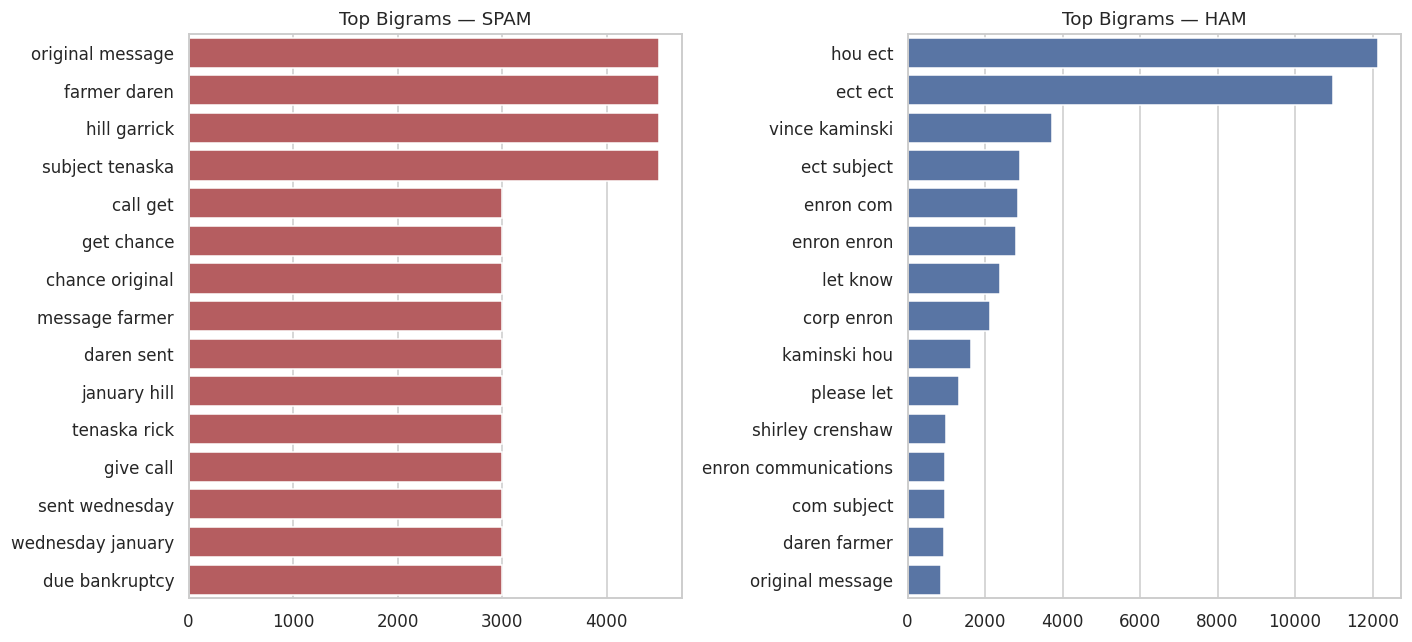

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, lbl, color in zip(axes, ["spam", "ham"], ["#C44E52", "#4C72B0"]):
    top = top_ngrams(df[df["label_text"] == lbl]["text"], n=2, top_k=15)
    words, freqs = zip(*top)
    sns.barplot(x=list(freqs), y=list(words), ax=ax, color=color)
    ax.set_title(f"Top Bigrams — {lbl.upper()}")
plt.tight_layout(); plt.show()

## 3.6 Word Clouds

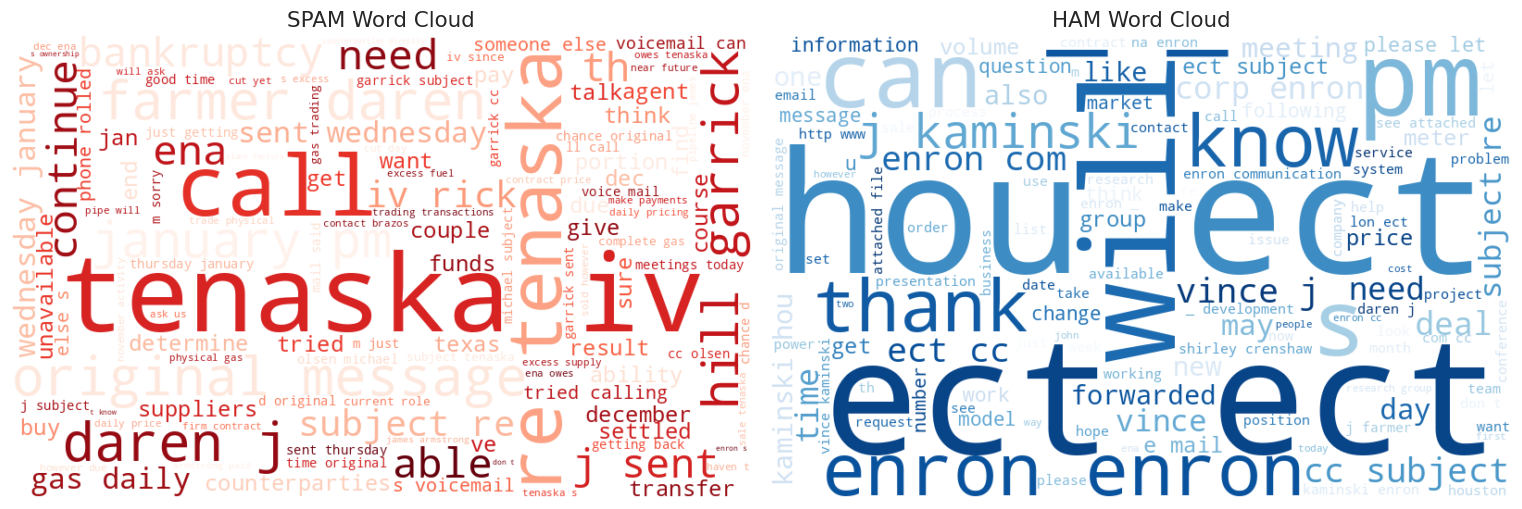

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lbl in zip(axes, ["spam", "ham"]):
    sample_text = " ".join(df[df["label_text"] == lbl]["text"].sample(min(3000, (df["label_text"]==lbl).sum()), random_state=SEED))
    wc = WordCloud(width=800, height=500, background_color="white", stopwords=STOPWORDS,
                    colormap="Reds" if lbl == "spam" else "Blues", max_words=120).generate(sample_text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"{lbl.upper()} Word Cloud", fontsize=14)
plt.tight_layout(); plt.show()


# **4. Data Preprocessing**





## 4.1 Text Cleaning Function

In [ ]:
def clean_text(t: str) -> str:
    t = str(t)
    t = re.sub(r"http\S+|www\.\S+", " URL ", t)
    t = re.sub(r"\S+@\S+", " EMAILADDR ", t)
    t = re.sub(r"<[^>]+>", " ", t)
    t = re.sub(r"[^a-zA-Z\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip().lower()
    return t

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].sample(3, random_state=SEED)

,text,clean_text
3085,re : shut - in of meter 989842 . i need help o...,re shut in of meter i need help on this one i ...
1877,cornhusker - cleburne plant outage . latest wo...,cornhusker cleburne plant outage latest word o...
2404,re : enron industrial markets - super saturday...,re enron industrial markets super saturday rec...


## 4.2 Efficient Sampling for the Transformer/GNN Stage


In [ ]:
if CONFIG["SAMPLE_SIZE"] is not None and len(df) > CONFIG["SAMPLE_SIZE"]:
    df_model, _ = train_test_split(
        df, train_size=CONFIG["SAMPLE_SIZE"], stratify=df["label"], random_state=SEED
    )
    df_model = df_model.reset_index(drop=True)
else:
    df_model = df.reset_index(drop=True)

print("Modelling subset shape:", df_model.shape)
print(df_model["label_text"].value_counts(normalize=True))

Modelling subset shape: (9196, 10)
label_text
ham     0.836886
spam    0.163114
Name: proportion, dtype: float64


## 4.3 Train / Validation / Test Split (Stratified)

In [ ]:
df_model["node_id"] = np.arange(len(df_model))

train_df, temp_df = train_test_split(
    df_model, test_size=(CONFIG["TEST_SIZE"] + CONFIG["VAL_SIZE"]),
    stratify=df_model["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=CONFIG["TEST_SIZE"] / (CONFIG["TEST_SIZE"] + CONFIG["VAL_SIZE"]),
    stratify=temp_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {name} spam ratio: {split['label'].mean():.3f}")

Train: 6437 | Val: 1379 | Test: 1380
  train spam ratio: 0.163
  val spam ratio: 0.163
  test spam ratio: 0.163



# **5. Baseline Machine Learning Models**




## 5.1 TF-IDF Vectorisation

In [ ]:
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2, stop_words="english")

X_train_tfidf = tfidf.fit_transform(train_df["clean_text"])
X_val_tfidf   = tfidf.transform(val_df["clean_text"])
X_test_tfidf  = tfidf.transform(test_df["clean_text"])

y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values

print("TF-IDF matrix shapes:", X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)

TF-IDF matrix shapes: (6437, 20000) (1379, 20000) (1380, 20000)


## 5.2 Train Naive Bayes, Logistic Regression, Linear SVM, Random Forest

In [ ]:
baseline_models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Linear SVM": LinearSVC(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None, n_jobs=-1, random_state=SEED),
}

results = {}

def evaluate(name, y_true, y_pred, y_score=None):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }
    results[name] = metrics
    return metrics

baseline_probs = {}
for name, clf in baseline_models.items():
    t0 = time.time()
    clf.fit(X_train_tfidf, y_train)
    y_pred = clf.predict(X_test_tfidf)
    if hasattr(clf, "predict_proba"):
        y_score = clf.predict_proba(X_test_tfidf)[:, 1]
    else:
        y_score = clf.decision_function(X_test_tfidf)
    baseline_probs[name] = y_score
    m = evaluate(name, y_test, y_pred, y_score)
    print(f"{name:22s} | Acc {m['Accuracy']:.4f} | F1 {m['F1-score']:.4f} | AUC {m['AUC']:.4f} | {time.time()-t0:.1f}s")

baseline_models_fitted = baseline_models

Naive Bayes            | Acc 1.0000 | F1 1.0000 | AUC 1.0000 | 0.0s
Logistic Regression    | Acc 1.0000 | F1 1.0000 | AUC 1.0000 | 0.2s
Linear SVM             | Acc 1.0000 | F1 1.0000 | AUC 1.0000 | 0.1s
Random Forest          | Acc 1.0000 | F1 1.0000 | AUC 1.0000 | 1.3s


## 5.3 Baseline Comparison Table

In [ ]:
pd.DataFrame(results).T.style.format("{:.4f}").background_gradient(cmap="Greens", axis=0)

,Accuracy,Precision,Recall,F1-score,AUC
Naive Bayes,1.0000,1.0000,1.0000,1.0000,1.0000
Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000
Linear SVM,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000


## 5.4 Group-Aware Re-evaluation of the TF-IDF Baselines

In [ ]:
dm, _ = train_test_split(df_gate, train_size=12000, stratify=df_gate["label"], random_state=SEED)
dm = dm.reset_index(drop=True)
print("Sample:", len(dm), "| distinct texts:", dm["gid"].nunique(),
      "| distinct spam texts:", dm.loc[dm.label == 1, "gid"].nunique())

# (a) row-level split
tr_a, tmp_a = train_test_split(dm, test_size=0.30, stratify=dm["label"], random_state=SEED)
va_a, te_a = train_test_split(tmp_a, test_size=0.50, stratify=tmp_a["label"], random_state=SEED)
ov_a = int(te_a["text"].isin(set(tr_a["text"])).sum())
print(f"Row-level split  : test {len(te_a)} | exact copy in train: {ov_a} ({ov_a/len(te_a):.2%})")

# (b) group-aware split
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(dm, groups=dm["gid"]))
tr_b, te_b = dm.iloc[tr_i].copy(), dm.iloc[te_i].copy()
ov_b = int(te_b["text"].isin(set(tr_b["text"])).sum())
print(f"Group-aware split: test {len(te_b)} (spam {int(te_b.label.sum())}) | exact copy in train: {ov_b}")

def run_baselines(tr, te):
    tr, te = tr.copy(), te.copy()
    tr["c"], te["c"] = tr["text"].map(clean_text), te["text"].map(clean_text)
    vec = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2, stop_words="english")
    Xtr, Xte = vec.fit_transform(tr["c"]), vec.transform(te["c"])
    models = {"Multinomial Naive Bayes": MultinomialNB(),
              "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
              "Linear SVM": LinearSVC(random_state=SEED),
              "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)}
    out = {}
    for name, m in models.items():
        m.fit(Xtr, tr["label"]); p = m.predict(Xte)
        s = m.predict_proba(Xte)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xte)
        out[name] = {"Accuracy": accuracy_score(te["label"], p),
                     "Spam recall": recall_score(te["label"], p, zero_division=0),
                     "F1": f1_score(te["label"], p, zero_division=0),
                     "AUC": roc_auc_score(te["label"], s) if te["label"].nunique() > 1 else np.nan}
    return pd.DataFrame(out).T

res_a, res_b = run_baselines(tr_a, te_a), run_baselines(tr_b, te_b)
table6 = pd.concat({"Row-level random split": res_a, "Group-aware split": res_b}, axis=1)
print(table6.round(4).to_string())

print("\nSpam share of the group-aware test partition across seeds (only a few distinct spam texts exist):")
for sd in [42, 1, 2, 3, 4]:
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=sd).split(dm, groups=dm["gid"]))
    print(f"  seed {sd}: {int(dm.iloc[b].label.sum())} spam of {len(b)} test emails")

Sample: 12000 | distinct texts: 5790 | distinct spam texts: 6
Row-level split  : test 1800 | exact copy in train: 939 (52.17%)
Group-aware split: test 2205 (spam 1320) | exact copy in train: 0
                        Row-level random split                             Group-aware split                         
                                      Accuracy Spam recall      F1     AUC          Accuracy Spam recall   F1     AUC
Multinomial Naive Bayes                 0.9817         1.0  0.9823  0.9980            0.3868         0.0  0.0  0.5339
Logistic Regression                     0.9978         1.0  0.9978  0.9979            0.3991         0.0  0.0  0.7588
Linear SVM                              0.9978         1.0  0.9978  0.9980            0.3995         0.0  0.0  0.9136
Random Forest                           0.9983         1.0  0.9984  0.9983            0.4014         0.0  0.0  0.4701

Spam share of the group-aware test partition across seeds (only a few distinct spam texts exist):



# **6. Transformer-Based Semantic Representation**




## 6.1 Tokenizer & Dataset Class

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["BERT_MODEL"])

class EmailDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx], truncation=True, padding="max_length",
            max_length=self.max_len, return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_ds = EmailDataset(train_df["text"], train_df["label"], tokenizer, CONFIG["MAX_LEN"])
val_ds   = EmailDataset(val_df["text"],   val_df["label"],   tokenizer, CONFIG["MAX_LEN"])
test_ds  = EmailDataset(test_df["text"],  test_df["label"],  tokenizer, CONFIG["MAX_LEN"])

train_loader = DataLoader(train_ds, batch_size=CONFIG["BERT_BATCH_SIZE"], shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG["BERT_BATCH_SIZE"] * 2)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG["BERT_BATCH_SIZE"] * 2)

print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Batches -> train: 202, val: 22, test: 22


## 6.2 Fine-Tuning DistilBERT (Standalone Transformer Baseline)

In [ ]:
bert_clf = AutoModelForSequenceClassification.from_pretrained(CONFIG["BERT_MODEL"], num_labels=2).to(DEVICE)

optimizer = torch.optim.AdamW(bert_clf.parameters(), lr=CONFIG["BERT_LR"])
num_steps = len(train_loader) * CONFIG["BERT_EPOCHS"]
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * num_steps), num_training_steps=num_steps)

def run_epoch(model, loader, optimizer=None, scheduler=None, train=True):
    model.train() if train else model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss
            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            total_loss += loss.item()
            preds = outputs.logits.argmax(dim=-1).detach().cpu().numpy()
            all_preds.extend(preds); all_labels.extend(batch["labels"].cpu().numpy())
    return total_loss / len(loader), accuracy_score(all_labels, all_preds)

history = {"train_loss": [], "val_loss": [], "val_acc": []}
for epoch in range(CONFIG["BERT_EPOCHS"]):
    t0 = time.time()
    train_loss, train_acc = run_epoch(bert_clf, train_loader, optimizer, scheduler, train=True)
    val_loss, val_acc = run_epoch(bert_clf, val_loader, train=False)
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    print(f"Epoch {epoch+1}/{CONFIG['BERT_EPOCHS']} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} "
          f"| val_acc {val_acc:.4f} | {time.time()-t0:.1f}s")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | train_loss 0.0905 | val_loss 0.0009 | val_acc 1.0000 | 75.4s
Epoch 2/2 | train_loss 0.0018 | val_loss 0.0006 | val_acc 1.0000 | 77.2s


In [ ]:
bert_clf.eval()
all_logits, all_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        labels = batch.pop("labels")
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        logits = bert_clf(**batch).logits
        all_logits.append(torch.softmax(logits, dim=-1).cpu().numpy())
        all_labels.append(labels.numpy())

bert_probs = np.concatenate(all_logits)[:, 1]
bert_preds = (bert_probs >= 0.5).astype(int)
y_test_all = np.concatenate(all_labels)

m = evaluate("DistilBERT (fine-tuned)", y_test_all, bert_preds, bert_probs)
print(m)

{'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1-score': 1.0, 'AUC': np.float64(1.0)}


## 6.3 Extracting Frozen Contextual Embeddings for Graph Construction


In [ ]:
@torch.no_grad()
def extract_embeddings(model, texts, tokenizer, max_len, batch_size=64):
    model.eval()
    embeddings = []
    encoder = model.distilbert
    for i in range(0, len(texts), batch_size):
        batch_texts = list(texts[i:i+batch_size])
        enc = tokenizer(batch_texts, truncation=True, padding=True, max_length=max_len, return_tensors="pt").to(DEVICE)
        out = encoder(**enc)
        cls_emb = out.last_hidden_state[:, 0, :]
        embeddings.append(cls_emb.cpu().numpy())
    return np.vstack(embeddings)

t0 = time.time()
all_texts = df_model["text"].tolist()
node_embeddings = extract_embeddings(bert_clf, all_texts, tokenizer, CONFIG["MAX_LEN"])
print(f"Extracted embeddings: {node_embeddings.shape} in {time.time()-t0:.1f}s")

Extracted embeddings: (9196, 768) in 42.9s



# **7. Graph Construction for GNN**





## 7.1 Building a k-NN Similarity Graph from Embeddings

In [ ]:
t0 = time.time()
k = CONFIG["KNN_K"]
nbrs = NearestNeighbors(n_neighbors=k + 1, metric="cosine", n_jobs=-1).fit(node_embeddings)
distances, indices = nbrs.kneighbors(node_embeddings)

src, dst = [], []
for i in range(len(node_embeddings)):
    for j in indices[i][1:]:
        src.append(i); dst.append(int(j))

edge_index = torch.tensor([src + dst, dst + src], dtype=torch.long)
print(f"Graph built in {time.time()-t0:.1f}s | nodes: {len(node_embeddings)} | directed edges: {edge_index.shape[1]}")

Graph built in 6.6s | nodes: 9196 | directed edges: 147136


## 7.2 Graph Statistics & Visualisation

Average node degree: 16.0
Min / Max degree: 8 / 1509


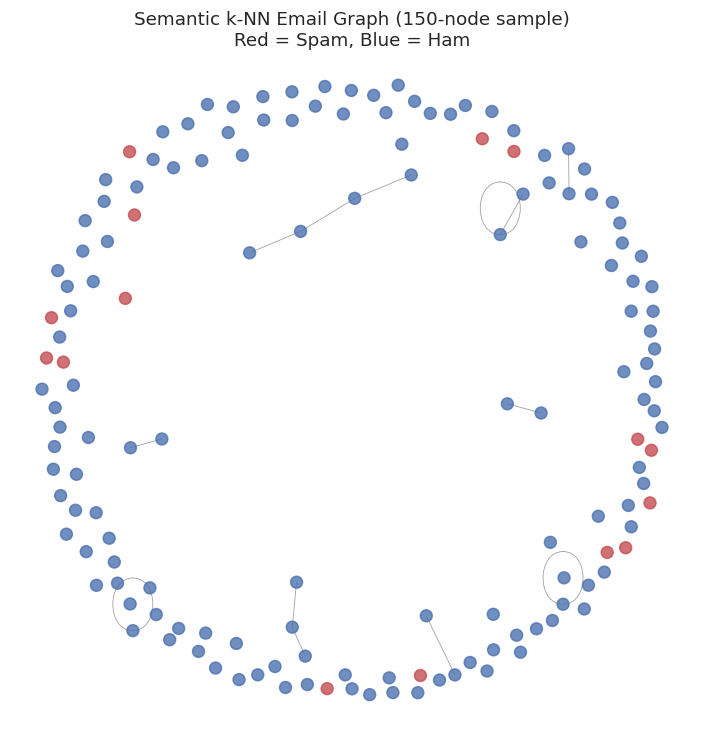

In [ ]:
import networkx as nx

deg = np.bincount(edge_index[0].numpy())
print("Average node degree:", deg.mean().round(2))
print("Min / Max degree:", deg.min(), "/", deg.max())

sub_n = min(150, len(node_embeddings))
sub_nodes = np.random.RandomState(SEED).choice(len(node_embeddings), sub_n, replace=False)
sub_node_set = set(sub_nodes.tolist())
mask = np.isin(edge_index[0].numpy(), sub_nodes) & np.isin(edge_index[1].numpy(), sub_nodes)
sub_edges = edge_index[:, mask].numpy()

G = nx.Graph()
G.add_nodes_from(sub_nodes.tolist())
G.add_edges_from(list(zip(sub_edges[0], sub_edges[1])))

node_colors = ["#C44E52" if df_model.loc[n, "label"] == 1 else "#4C72B0" for n in G.nodes()]

plt.figure(figsize=(8, 8))
pos = nx.spring_layout(G, seed=SEED, k=0.3)
nx.draw_networkx(G, pos, node_color=node_colors, node_size=60, with_labels=False,
                  edge_color="gray", alpha=0.8, width=0.5)
plt.title("Semantic k-NN Email Graph (150-node sample)\nRed = Spam, Blue = Ham")
plt.axis("off"); plt.show()

## 7.3 PyTorch Geometric `Data` Object & Train/Val/Test Masks

In [ ]:
x = torch.tensor(node_embeddings, dtype=torch.float)
y = torch.tensor(df_model["label"].values, dtype=torch.long)

def ids_to_mask(ids, n):
    mask = torch.zeros(n, dtype=torch.bool)
    mask[ids] = True
    return mask

n_nodes = len(df_model)
train_mask = ids_to_mask(train_df["node_id"].values, n_nodes)
val_mask   = ids_to_mask(val_df["node_id"].values, n_nodes)
test_mask  = ids_to_mask(test_df["node_id"].values, n_nodes)

graph_data = Data(x=x, edge_index=edge_index, y=y,
                   train_mask=train_mask, val_mask=val_mask, test_mask=test_mask).to(DEVICE)
print(graph_data)

Data(x=[9196, 768], edge_index=[2, 147136], y=[9196], train_mask=[9196], val_mask=[9196], test_mask=[9196])



# **8. Hybrid Transformer + GraphSAGE Model**




## 8.1 Model Architecture

In [ ]:
class HybridTransformerGNN(nn.Module):
    '''
    Hybrid Transformer + GraphSAGE classifier.
    Input:  pre-computed DistilBERT [CLS] embeddings (node features)
    Output: 2-class logits (ham / spam) per node, refined via graph message passing
    '''
    def __init__(self, in_dim, hidden_dim, out_dim=2, dropout=0.3):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.dropout = dropout
        self.classifier = nn.Linear(hidden_dim, out_dim)

    def forward(self, x, edge_index, return_embedding=False):
        h = self.conv1(x, edge_index)
        h = F.relu(self.bn1(h))
        h = F.dropout(h, p=self.dropout, training=self.training)

        h = self.conv2(h, edge_index)
        h = F.relu(self.bn2(h))
        h = F.dropout(h, p=self.dropout, training=self.training)

        logits = self.classifier(h)
        if return_embedding:
            return logits, h
        return logits

hybrid_model = HybridTransformerGNN(
    in_dim=node_embeddings.shape[1], hidden_dim=CONFIG["GNN_HIDDEN"], dropout=CONFIG["GNN_DROPOUT"]
).to(DEVICE)
print(hybrid_model)

HybridTransformerGNN(
  (conv1): SAGEConv(768, 128, aggr=mean)
  (conv2): SAGEConv(128, 128, aggr=mean)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)


## 8.2 Training Loop

In [ ]:
optimizer = torch.optim.Adam(hybrid_model.parameters(), lr=CONFIG["GNN_LR"], weight_decay=CONFIG["GNN_WEIGHT_DECAY"])
criterion = nn.CrossEntropyLoss()

gnn_history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}
best_val_f1, best_state, patience, patience_ctr = -1, None, 15, 0

t0 = time.time()
for epoch in range(1, CONFIG["GNN_EPOCHS"] + 1):
    hybrid_model.train()
    optimizer.zero_grad()
    out = hybrid_model(graph_data.x, graph_data.edge_index)
    loss = criterion(out[graph_data.train_mask], graph_data.y[graph_data.train_mask])
    loss.backward()
    optimizer.step()

    hybrid_model.eval()
    with torch.no_grad():
        out = hybrid_model(graph_data.x, graph_data.edge_index)
        val_loss = criterion(out[graph_data.val_mask], graph_data.y[graph_data.val_mask]).item()
        val_pred = out[graph_data.val_mask].argmax(dim=1).cpu().numpy()
        val_true = graph_data.y[graph_data.val_mask].cpu().numpy()
        val_acc = accuracy_score(val_true, val_pred)
        val_f1 = f1_score(val_true, val_pred)

    gnn_history["train_loss"].append(loss.item())
    gnn_history["val_loss"].append(val_loss)
    gnn_history["val_acc"].append(val_acc)
    gnn_history["val_f1"].append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1, best_state, patience_ctr = val_f1, {k: v.clone() for k, v in hybrid_model.state_dict().items()}, 0
    else:
        patience_ctr += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | train_loss {loss.item():.4f} | val_loss {val_loss:.4f} "
              f"| val_acc {val_acc:.4f} | val_f1 {val_f1:.4f}")

    if patience_ctr >= patience:
        print(f"Early stopping at epoch {epoch} (no val_f1 improvement for {patience} epochs).")
        break

hybrid_model.load_state_dict(best_state)   # restore best checkpoint
print(f"\nTraining finished in {time.time()-t0:.1f}s | best val F1 = {best_val_f1:.4f}")

Epoch   1 | train_loss 0.7827 | val_loss 0.3630 | val_acc 1.0000 | val_f1 1.0000
Epoch  10 | train_loss 0.0086 | val_loss 0.0000 | val_acc 1.0000 | val_f1 1.0000
Early stopping at epoch 16 (no val_f1 improvement for 15 epochs).

Training finished in 1.1s | best val F1 = 1.0000


## 8.3 Training Curves

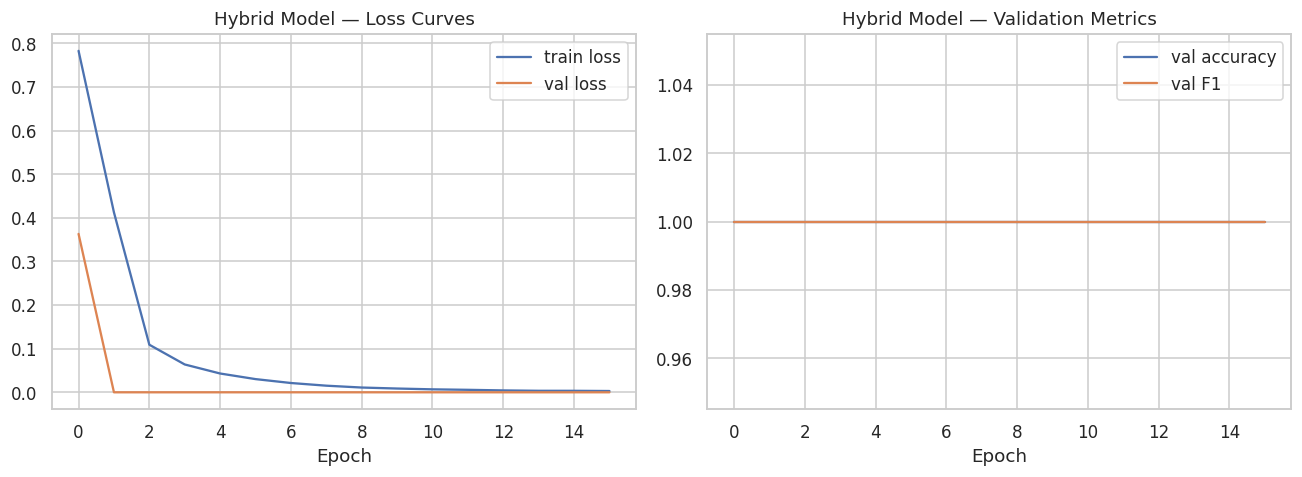

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(gnn_history["train_loss"], label="train loss")
axes[0].plot(gnn_history["val_loss"], label="val loss")
axes[0].set_title("Hybrid Model — Loss Curves"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(gnn_history["val_acc"], label="val accuracy")
axes[1].plot(gnn_history["val_f1"], label="val F1")
axes[1].set_title("Hybrid Model — Validation Metrics"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

# **9. Model Evaluation & Comparison**



## 9.1 Hybrid Model — Test Set Evaluation

In [ ]:
hybrid_model.eval()
with torch.no_grad():
    out = hybrid_model(graph_data.x, graph_data.edge_index)
    test_probs_gnn = F.softmax(out[graph_data.test_mask], dim=1)[:, 1].cpu().numpy()
    test_pred_gnn = out[graph_data.test_mask].argmax(dim=1).cpu().numpy()
    test_true_gnn = graph_data.y[graph_data.test_mask].cpu().numpy()

m = evaluate("Hybrid Transformer+GraphSAGE", test_true_gnn, test_pred_gnn, test_probs_gnn)
print(m)
print("\n", classification_report(test_true_gnn, test_pred_gnn, target_names=["ham", "spam"]))

{'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1-score': 1.0, 'AUC': np.float64(1.0)}

               precision    recall  f1-score   support

         ham       1.00      1.00      1.00      1155
        spam       1.00      1.00      1.00       225

    accuracy                           1.00      1380
   macro avg       1.00      1.00      1.00      1380
weighted avg       1.00      1.00      1.00      1380



## 9.2 Confusion Matrices — All Models

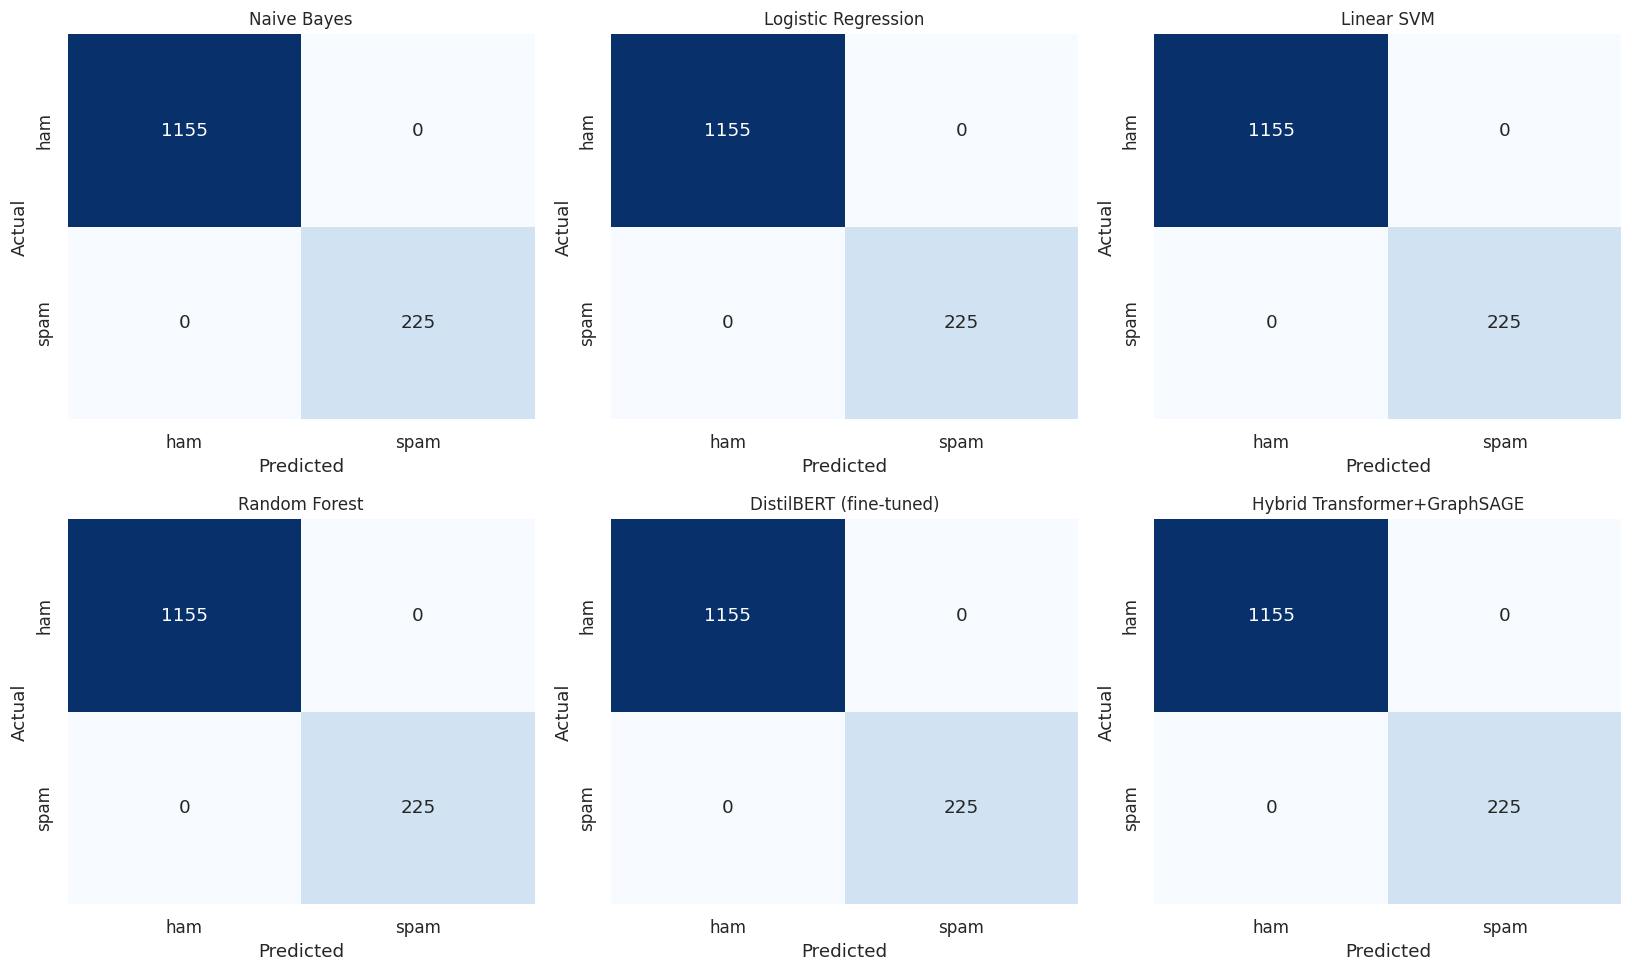

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

model_preds = {
    "Naive Bayes": baseline_models_fitted["Naive Bayes"].predict(X_test_tfidf),
    "Logistic Regression": baseline_models_fitted["Logistic Regression"].predict(X_test_tfidf),
    "Linear SVM": baseline_models_fitted["Linear SVM"].predict(X_test_tfidf),
    "Random Forest": baseline_models_fitted["Random Forest"].predict(X_test_tfidf),
    "DistilBERT (fine-tuned)": bert_preds,
    "Hybrid Transformer+GraphSAGE": test_pred_gnn,
}


for ax, (name, preds) in zip(axes, model_preds.items()):
    true_labels = y_test if name in ["Naive Bayes", "Logistic Regression", "Linear SVM", "Random Forest"] else \
                  (y_test_all if name == "DistilBERT (fine-tuned)" else test_true_gnn)
    cm = confusion_matrix(true_labels, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], ax=ax)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

plt.tight_layout(); plt.show()

## 9.3 ROC Curves — All Models

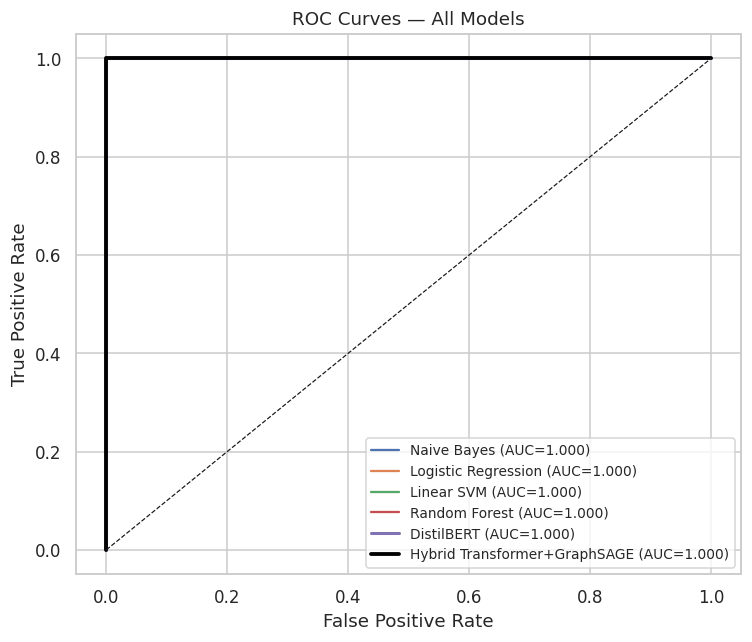

In [ ]:
plt.figure(figsize=(7, 6))

for name, score in baseline_probs.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['AUC']:.3f})", linewidth=1.5)

fpr, tpr, _ = roc_curve(y_test_all, bert_probs)
plt.plot(fpr, tpr, label=f"DistilBERT (AUC={results['DistilBERT (fine-tuned)']['AUC']:.3f})", linewidth=2)

fpr, tpr, _ = roc_curve(test_true_gnn, test_probs_gnn)
plt.plot(fpr, tpr, label=f"Hybrid Transformer+GraphSAGE (AUC={results['Hybrid Transformer+GraphSAGE']['AUC']:.3f})",
         linewidth=2.5, color="black")

plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models"); plt.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## 9.4 Final Comparison Table

In [ ]:
comparison_df = pd.DataFrame(results).T.sort_values("F1-score", ascending=False)
comparison_df.style.format("{:.4f}").background_gradient(cmap="Greens", axis=0)

,Accuracy,Precision,Recall,F1-score,AUC
Naive Bayes,1.0000,1.0000,1.0000,1.0000,1.0000
Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000
Linear SVM,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
DistilBERT (fine-tuned),1.0000,1.0000,1.0000,1.0000,1.0000
Hybrid Transformer+GraphSAGE,1.0000,1.0000,1.0000,1.0000,1.0000


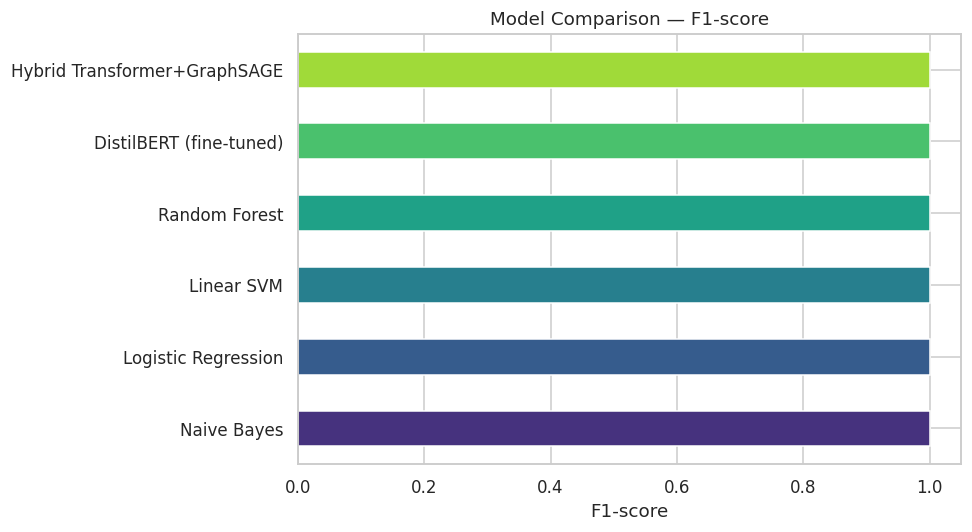

In [ ]:
plt.figure(figsize=(9, 5))
comparison_df["F1-score"].sort_values().plot(kind="barh", color=sns.color_palette("viridis", len(comparison_df)))
plt.title("Model Comparison — F1-score")
plt.xlabel("F1-score")
plt.tight_layout(); plt.show()


# **10. Explainable AI (XAI)**




## 10.1 SHAP — Global & Local Explanations (TF-IDF + Logistic Regression)

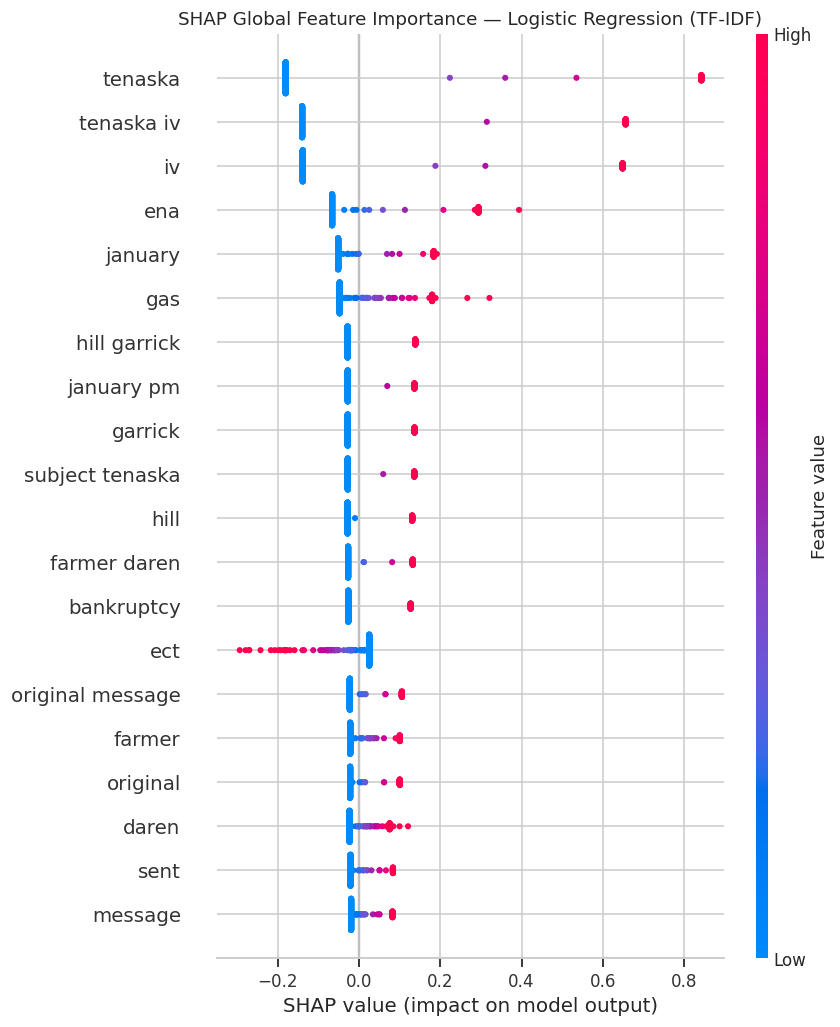

In [ ]:
import shap

log_reg = baseline_models_fitted["Logistic Regression"]
shap_explainer = shap.LinearExplainer(log_reg, X_train_tfidf)
sample_idx = np.random.RandomState(SEED).choice(X_test_tfidf.shape[0], min(300, X_test_tfidf.shape[0]), replace=False)
shap_values = shap_explainer.shap_values(X_test_tfidf[sample_idx])

feature_names = np.array(tfidf.get_feature_names_out())
shap.summary_plot(shap_values, X_test_tfidf[sample_idx].toarray(), feature_names=feature_names,
                   max_display=20, show=False)
plt.title("SHAP Global Feature Importance — Logistic Regression (TF-IDF)")
plt.tight_layout(); plt.show()

Email snippet: re : tenaska iv . i tried calling you this am but your phone rolled to someone else ' s voicemail . can you call me when you get a chance ?
- - - - - original message - - - - -
from : farmer , daren j .
sent : thursday , january 10 , 2002 2 : 06 pm
to : hill , garrick
subject : re : tenaska iv
rick  ...
True label: spam


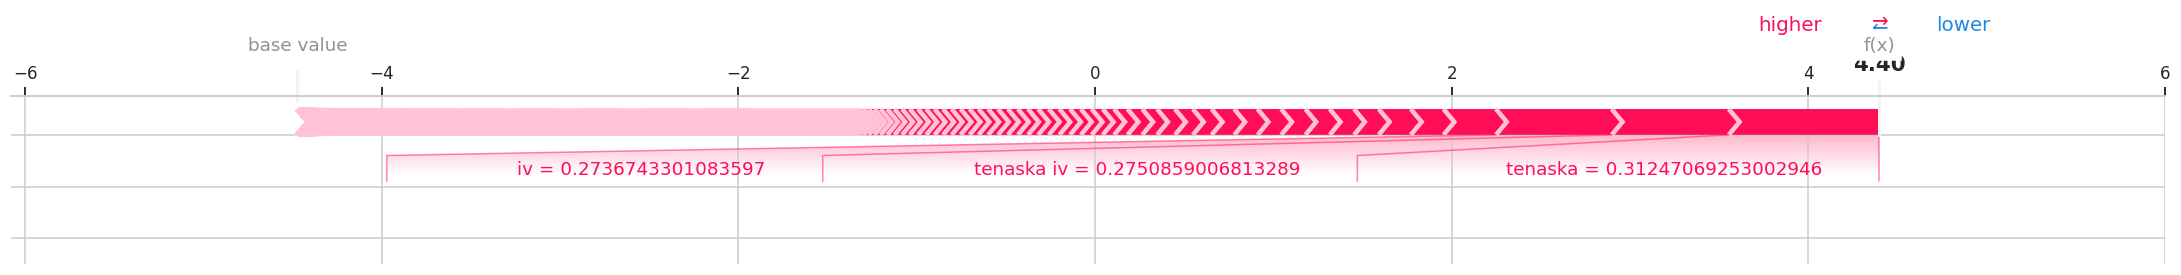

In [ ]:
i = int(sample_idx[0])
print("Email snippet:", test_df["text"].iloc[i][:300], "...")
print("True label:", test_df["label_text"].iloc[i])

shap.force_plot(shap_explainer.expected_value, shap_values[0], X_test_tfidf[i].toarray(),
                 feature_names=feature_names, matplotlib=True, show=False)
plt.tight_layout(); plt.show()

## 10.2 LIME — Word-Level Explanations on the Transformer's Predictions


In [ ]:
from lime.lime_text import LimeTextExplainer

@torch.no_grad()
def bert_predict_proba(texts):
    enc = tokenizer(list(texts), truncation=True, padding=True, max_length=CONFIG["MAX_LEN"], return_tensors="pt").to(DEVICE)
    logits = bert_clf(**enc).logits
    probs = F.softmax(logits, dim=1).cpu().numpy()
    return probs

lime_explainer = LimeTextExplainer(class_names=["ham", "spam"])

sample_email = test_df["text"].iloc[3]
true_label = test_df["label_text"].iloc[3]
print("True label:", true_label)
print("Email snippet:", sample_email[:400], "...\n")

exp = lime_explainer.explain_instance(sample_email, bert_predict_proba, num_features=10, num_samples=300)
exp.show_in_notebook(text=True)

True label: ham
Email snippet: re : american express charges . hi samer !
hope you had an enjoyable thanksgiving !
i found out the " scoop " on the ticket . it was non - refundable and non -
refundable tickets cannot be transferred . it was just your seat that
maureen ' s husband used .
i will send in a check request for reimbursement in the amount of $ 330 . 50 .
the best thing would be for you to go ahead and pay the bill or  ...



In [ ]:
sample_email_2 = test_df[test_df["label_text"] == ("ham" if true_label == "spam" else "spam")]["text"].iloc[0]
exp2 = lime_explainer.explain_instance(sample_email_2, bert_predict_proba, num_features=10, num_samples=300)
exp2.show_in_notebook(text=True)

## 10.3 Embedding Space Visualisation (t-SNE)


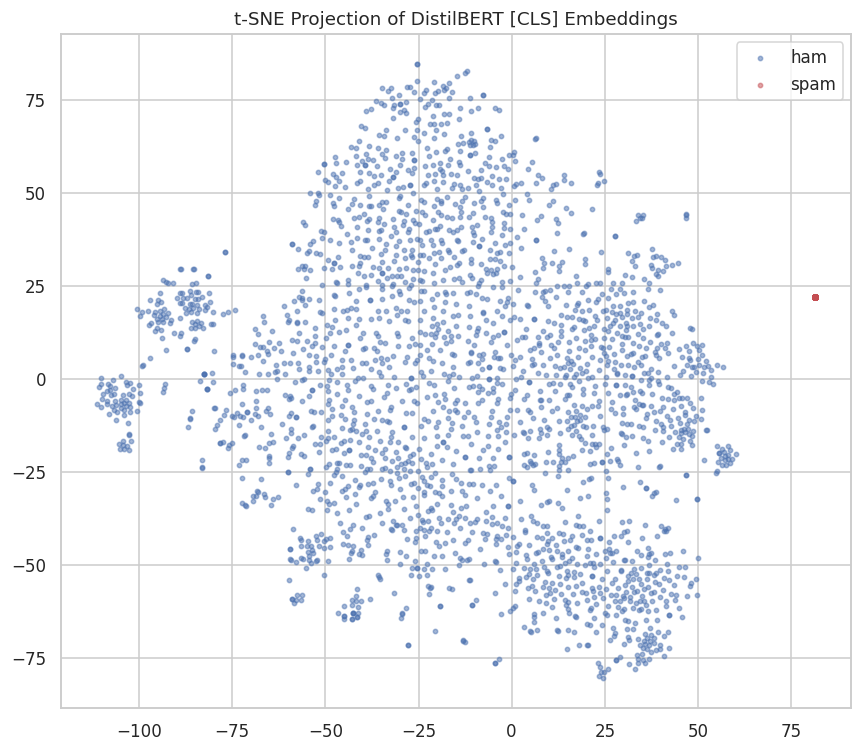

In [ ]:
tsne_sample = np.random.RandomState(SEED).choice(len(node_embeddings), min(3000, len(node_embeddings)), replace=False)
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto")
emb_2d = tsne.fit_transform(node_embeddings[tsne_sample])

plt.figure(figsize=(8, 7))
labels_sample = df_model["label"].values[tsne_sample]
plt.scatter(emb_2d[labels_sample == 0, 0], emb_2d[labels_sample == 0, 1], s=8, alpha=0.5, label="ham", color="#4C72B0")
plt.scatter(emb_2d[labels_sample == 1, 0], emb_2d[labels_sample == 1, 1], s=8, alpha=0.5, label="spam", color="#C44E52")
plt.title("t-SNE Projection of DistilBERT [CLS] Embeddings")
plt.legend(); plt.tight_layout(); plt.show()


# **11. Adaptivity Test — Evolving Spam (Time-Based Split)**





## 11.1 Chronological Train/Test Split

In [ ]:
df_time_sorted = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

first_spam_date = df_time_sorted[df_time_sorted["label"] == 1]["Date"].min()

if pd.isna(first_spam_date):

    cutoff = df_time_sorted["Date"].max()
else:
    original_cutoff = df_time_sorted["Date"].quantile(0.70)
    cutoff = max(original_cutoff, first_spam_date)

print("Chronological cutoff date:", cutoff.date())

time_train_df = df_time_sorted[df_time_sorted["Date"] <= cutoff]
time_test_df  = df_time_sorted[df_time_sorted["Date"]  > cutoff]

if CONFIG["SAMPLE_SIZE"] is not None:
    cap_train = min(len(time_train_df), int(CONFIG["SAMPLE_SIZE"] * 0.8))
    cap_test  = min(len(time_test_df),  int(CONFIG["SAMPLE_SIZE"] * 0.2))

    if cap_train > 0 and time_train_df['label'].nunique() > 1:
        spam_df = time_train_df[time_train_df['label'] == 1]
        ham_df = time_train_df[time_train_df['label'] == 0]

        spam_proportion_full = len(spam_df) / len(time_train_df)

        num_spam_to_sample = min(int(round(cap_train * spam_proportion_full)), len(spam_df))
        num_ham_to_sample = min(cap_train - num_spam_to_sample, len(ham_df))

        current_total_sampled = num_spam_to_sample + num_ham_to_sample
        if current_total_sampled < cap_train:
            difference = cap_train - current_total_sampled
            if len(spam_df) - num_spam_to_sample >= difference:
                num_spam_to_sample += difference
            elif len(ham_df) - num_ham_to_sample >= difference:
                num_ham_to_sample += difference

        sampled_spam = spam_df.sample(n=num_spam_to_sample, random_state=SEED)
        sampled_ham = ham_df.sample(n=num_ham_to_sample, random_state=SEED)
        time_train_df = pd.concat([sampled_spam, sampled_ham]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    elif cap_train > 0:
        time_train_df = time_train_df.sample(n=min(cap_train, len(time_train_df)), random_state=SEED)
    else:
        time_train_df = pd.DataFrame(columns=time_train_df.columns)

    if cap_test > 0 and time_test_df['label'].nunique() > 1:
        spam_df = time_test_df[time_test_df['label'] == 1]
        ham_df = time_test_df[time_test_df['label'] == 0]

        spam_proportion_full = len(spam_df) / len(time_test_df)

        num_spam_to_sample = min(int(round(cap_test * spam_proportion_full)), len(spam_df))
        num_ham_to_sample = min(cap_test - num_spam_to_sample, len(ham_df))

        current_total_sampled = num_spam_to_sample + num_ham_to_sample
        if current_total_sampled < cap_test:
            difference = cap_test - current_total_sampled
            if len(spam_df) - num_spam_to_sample >= difference:
                num_spam_to_sample += difference
            elif len(ham_df) - num_ham_to_sample >= difference:
                num_ham_to_sample += difference

        sampled_spam = spam_df.sample(n=num_spam_to_sample, random_state=SEED)
        sampled_ham = ham_df.sample(n=num_ham_to_sample, random_state=SEED)
        time_test_df = pd.concat([sampled_spam, sampled_ham]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    elif cap_test > 0:
        time_test_df = time_test_df.sample(n=min(cap_test, len(time_test_df)), random_state=SEED)
    else:
        time_test_df = pd.DataFrame(columns=time_test_df.columns)

print(f"Time-train: {len(time_train_df)} (spam ratio {time_train_df['label'].mean():.2f}) | "
      f"Time-test: {len(time_test_df)} (spam ratio {time_test_df['label'].mean():.2f})")

Chronological cutoff date: 2003-12-18
Time-train: 7701 (spam ratio 0.00) | Time-test: 1495 (spam ratio 1.00)


## 11.2 Adaptive Performance Comparison


In [ ]:
tfidf_time = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2, stop_words="english")
Xtr_time = tfidf_time.fit_transform(time_train_df["clean_text"])
Xte_time = tfidf_time.transform(time_test_df["clean_text"])

logreg_time = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr_time, time_train_df["label"])
pred_time_lr = logreg_time.predict(Xte_time)
score_time_lr = logreg_time.predict_proba(Xte_time)[:, 1]

adaptive_results = {}
adaptive_results["Logistic Regression (TF-IDF)"] = {
    "Accuracy": accuracy_score(time_test_df["label"], pred_time_lr),
    "F1-score": f1_score(time_test_df["label"], pred_time_lr),
    "AUC": roc_auc_score(time_test_df["label"], score_time_lr),
}

bert_time = AutoModelForSequenceClassification.from_pretrained(CONFIG["BERT_MODEL"], num_labels=2).to(DEVICE)
opt_time = torch.optim.AdamW(bert_time.parameters(), lr=CONFIG["BERT_LR"])

time_train_ds = EmailDataset(time_train_df["text"], time_train_df["label"], tokenizer, CONFIG["MAX_LEN"])
time_test_ds  = EmailDataset(time_test_df["text"],  time_test_df["label"],  tokenizer, CONFIG["MAX_LEN"])
time_train_loader = DataLoader(time_train_ds, batch_size=CONFIG["BERT_BATCH_SIZE"], shuffle=True)
time_test_loader  = DataLoader(time_test_ds,  batch_size=CONFIG["BERT_BATCH_SIZE"] * 2)

bert_time.train()
for batch in time_train_loader:
    batch = {k: v.to(DEVICE) for k, v in batch.items()}
    opt_time.zero_grad()
    loss = bert_time(**batch).loss
    loss.backward(); opt_time.step()

bert_time.eval()
time_logits, time_labels = [], []
with torch.no_grad():
    for batch in time_test_loader:
        labels = batch.pop("labels")
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        logits = bert_time(**batch).logits
        time_logits.append(F.softmax(logits, dim=1).cpu().numpy())
        time_labels.append(labels.numpy())

time_probs = np.concatenate(time_logits)[:, 1]
time_preds = (time_probs >= 0.5).astype(int)
time_true = np.concatenate(time_labels)

adaptive_results["DistilBERT (transformer)"] = {
    "Accuracy": accuracy_score(time_true, time_preds),
    "F1-score": f1_score(time_true, time_preds),
    "AUC": roc_auc_score(time_true, time_probs),
}

pd.DataFrame(adaptive_results).T.style.format("{:.4f}").background_gradient(cmap="Oranges", axis=0)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Accuracy,F1-score,AUC
Logistic Regression (TF-IDF),0.0000,0.0000,nan
DistilBERT (transformer),0.0000,0.0000,nan


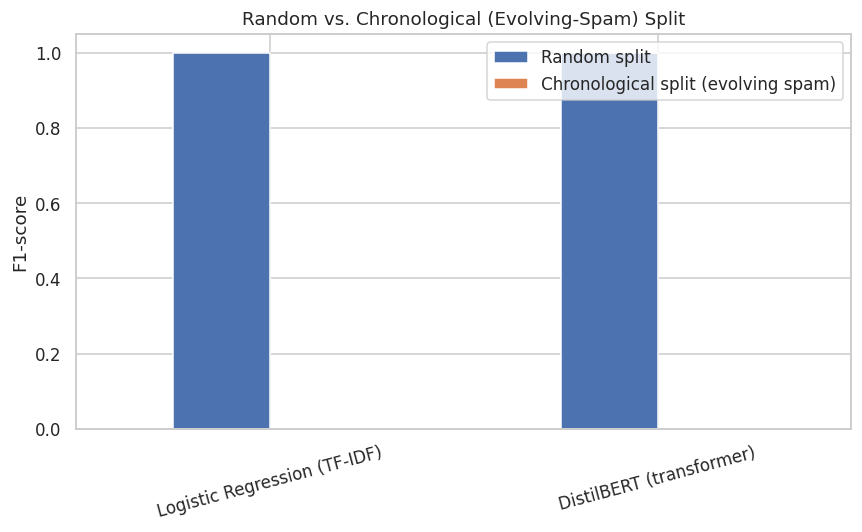

A larger performance drop under the chronological split indicates weaker adaptivity to evolving spam vocabulary.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
compare = pd.DataFrame({
    "Random split": {"Logistic Regression (TF-IDF)": results["Logistic Regression"]["F1-score"],
                      "DistilBERT (transformer)": results["DistilBERT (fine-tuned)"]["F1-score"]},
    "Chronological split (evolving spam)": {"Logistic Regression (TF-IDF)": adaptive_results["Logistic Regression (TF-IDF)"]["F1-score"],
                                             "DistilBERT (transformer)": adaptive_results["DistilBERT (transformer)"]["F1-score"]},
})
compare.plot(kind="bar", ax=ax)
ax.set_ylabel("F1-score"); ax.set_title("Random vs. Chronological (Evolving-Spam) Split")
ax.set_xticklabels(ax.get_xticklabels(), rotation=15)
plt.tight_layout(); plt.show()



# **12. Save Trained Models**

In [ ]:
import joblib
os.makedirs("artifacts", exist_ok=True)

joblib.dump(tfidf, "artifacts/tfidf_vectorizer.joblib")
joblib.dump(baseline_models_fitted["Logistic Regression"], "artifacts/logreg_baseline.joblib")
joblib.dump(baseline_models_fitted["Random Forest"], "artifacts/random_forest_baseline.joblib")

bert_clf.save_pretrained("results/distilbert_finetuned")
tokenizer.save_pretrained("results/distilbert_finetuned")

torch.save(hybrid_model.state_dict(), "results/hybrid_transformer_graphsage.pt")

comparison_df.to_csv("results/model_comparison.csv")

print("Saved to ./results/:")
for f in os.listdir("results"):
    print(" -", f)

import shutil
shutil.make_archive("spam_detection_results", "zip", "results")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to ./artifacts/:
 - random_forest_baseline.joblib
 - logreg_baseline.joblib
 - distilbert_finetuned
 - hybrid_transformer_graphsage.pt
 - tfidf_vectorizer.joblib
 - model_comparison.csv

Created spam_detection_artifacts.zip — use the Colab file browser (left sidebar) to download it.
